# 02 - Data Preparation
Sampling, pembersihan, pembentukan RFM, transformasi log, dan standarisasi.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rfm_kmeans import config
cfg = config.load_config()
SEED = cfg["seed"]
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
from rfm_kmeans import data_loader, sampling, cleaning, features, preprocessing
OUT = config.resolve(cfg, "processed_dir")
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
raw = data_loader.load_raw(config.resolve(cfg, "raw_csv"), config.resolve(cfg, "raw_xlsx"))
sample = sampling.sample_by_customer(raw, cfg["sampling"]["target_rows"], SEED)
sample.to_csv(OUT / "sample_transactions.csv", index=False)
len(sample)

50230

## Pembersihan
Periksa dulu kode non-produk di notebook 01 sebelum `drop_non_product` diaktifkan.

In [3]:
clean, log = cleaning.clean_transactions(sample, cfg["cleaning"])
clean.to_csv(OUT / "clean_transactions.csv", index=False)
pd.Series(log)

awal                              50,230.00
setelah_hapus_CustomerID_kosong   50,230.00
setelah_hapus_duplikat            49,548.00
setelah_hapus_pembatalan          48,293.00
setelah_hapus_nilai_tidak_valid   48,290.00
setelah_hapus_non_produk          48,150.00
akhir                             48,150.00
persen_tersisa                        95.86
dtype: float64

## RFM

In [4]:
rfm = features.build_rfm(clean, cfg["rfm"]["reference_offset_days"])
rfm.to_csv(OUT / "rfm.csv", index=False)
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,593.00,593.00,593.00,593.00
mean,"15,421.64",89.67,4.18,"1,841.35"
std,"1,691.22",100.63,5.72,"5,981.73"
min,"12,350.00",1.00,1.00,3.75
25%,"13,938.00",18.00,1.00,271.85
50%,"15,514.00",46.00,2.00,713.89
75%,"16,842.00",122.00,5.00,"1,628.56"
max,"18,282.00",373.00,62.00,"91,062.38"


## Transformasi log dan standarisasi

In [5]:
X, scaler = preprocessing.transform_rfm(rfm, cfg["preprocessing"]["log_transform"])
X.to_csv(OUT / "rfm_scaled.csv")
print("Skewness sebelum:\n", rfm[["Recency", "Frequency", "Monetary"]].skew().round(2))
print("Skewness sesudah:\n", X.skew().round(2))

Skewness sebelum:
 Recency      1.38
Frequency    5.13
Monetary    11.09
dtype: float64
Skewness sesudah:
 Recency     -0.34
Frequency    1.01
Monetary     0.17
dtype: float64


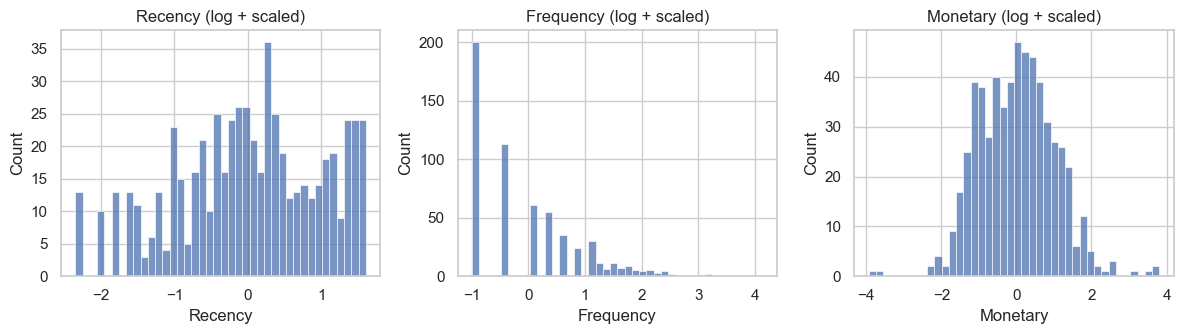

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, c in zip(ax, X.columns):
    sns.histplot(X[c], bins=40, ax=a); a.set_title(f"{c} (log + scaled)")
plt.tight_layout(); plt.show()